Q1. Student Performance and Correlation Analysis

Correlation Matrix:
             Study_Hours  Attendance  Assignments  Sleep_Hours   Marks
Study_Hours       1.0000      0.9896       0.9768      -0.9685  0.9815
Attendance        0.9896      1.0000       0.9931      -0.9621  0.9930
Assignments       0.9768      0.9931       1.0000      -0.9525  0.9907
Sleep_Hours      -0.9685     -0.9621      -0.9525       1.0000 -0.9738
Marks             0.9815      0.9930       0.9907      -0.9738  1.0000


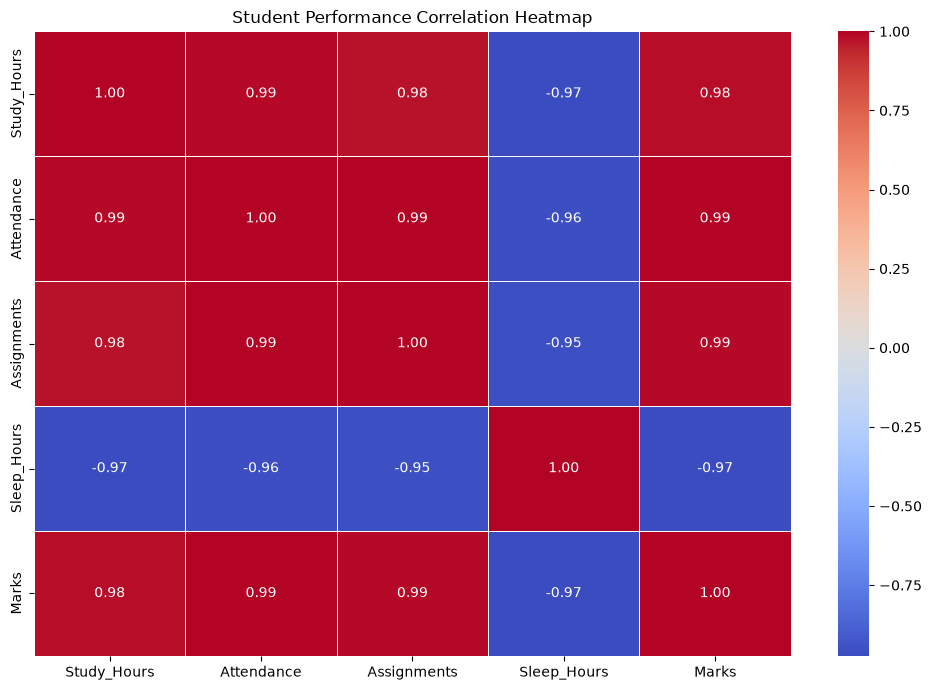


Feature Ranking:
Attendance     0.993050
Assignments    0.990728
Study_Hours    0.981485
Sleep_Hours    0.973826
Name: Marks, dtype: float64

Strongest Positive Relationship:
Attendance

Strongest Negative Relationship:
Sleep_Hours


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create DataFrame
df = pd.DataFrame({
    "Study_Hours": [2, 3, 4, 5, 6, 7, 8, 9, 3, 6, 8, 4],
    "Attendance": [55, 60, 65, 70, 75, 80, 85, 95, 62, 78, 90, 68],
    "Assignments": [3, 4, 5, 5, 6, 7, 8, 10, 4, 7, 9, 5],
    "Sleep_Hours": [9, 8, 8, 7, 7, 6, 6, 5, 9, 7, 5, 8],
    "Marks": [40, 45, 50, 58, 65, 72, 78, 95, 43, 70, 90, 52]
})

# Calculate correlation matrix
corr = df.corr()

print("Correlation Matrix:")
print(corr.round(4))

# Create annotated heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Student Performance Correlation Heatmap")
plt.tight_layout()
plt.show()

# Rank features by absolute correlation with Marks
ranking = corr['Marks'].drop('Marks').abs().sort_values(
    ascending=False
)

print("\nFeature Ranking:")
print(ranking)

# Strongest positive and negative relationships
print("\nStrongest Positive Relationship:")
print(corr['Marks'].drop('Marks').idxmax())

print("\nStrongest Negative Relationship:")
print(corr['Marks'].drop('Marks').idxmin())


(b) Remove the student with the highest marks and recalculate the correlation matrix.

Student with Highest Marks:
Study_Hours     9
Attendance     95
Assignments    10
Sleep_Hours     5
Marks          95
Name: 7, dtype: int64

Updated Correlation Matrix:
             Study_Hours  Attendance  Assignments  Sleep_Hours   Marks
Study_Hours       1.0000      0.9877       0.9732      -0.9591  0.9771
Attendance        0.9877      1.0000       0.9909      -0.9528  0.9901
Assignments       0.9732      0.9909       1.0000      -0.9432  0.9871
Sleep_Hours      -0.9591     -0.9528      -0.9432       1.0000 -0.9692
Marks             0.9771      0.9901       0.9871      -0.9692  1.0000


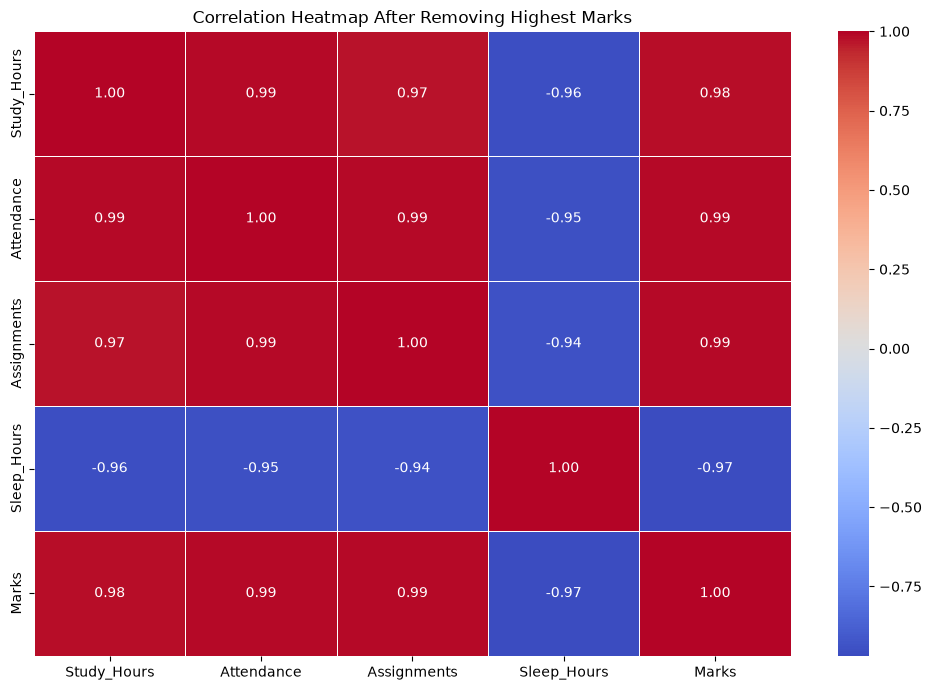


Correlation Comparison:
             Before   After
Study_Hours  0.9815  0.9771
Attendance   0.9930  0.9901
Assignments  0.9907  0.9871
Sleep_Hours -0.9738 -0.9692


In [2]:

# Find student with highest marks
highest_index = df['Marks'].idxmax()

print("Student with Highest Marks:")
print(df.loc[highest_index])

# Remove that student
new_df = df.drop(highest_index)

# Recalculate correlation matrix
new_corr = new_df.corr()

print("\nUpdated Correlation Matrix:")
print(new_corr.round(4))

# Create updated heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    new_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap After Removing Highest Marks")
plt.tight_layout()
plt.show()

# Compare feature-to-marks correlations
comparison = pd.DataFrame({
    "Before": corr['Marks'].drop('Marks'),
    "After": new_corr['Marks'].drop('Marks')
})

print("\nCorrelation Comparison:")
print(comparison.round(4))


Q2. Detecting Redundant Features in a Housing Dataset

Correlation Matrix:
             Area_sqft  Area_sqm  Bedrooms  Age_Years  Price_Lakhs
Area_sqft       1.0000    1.0000    0.9578    -0.9907       0.9992
Area_sqm        1.0000    1.0000    0.9578    -0.9907       0.9992
Bedrooms        0.9578    0.9578    1.0000    -0.9698       0.9548
Age_Years      -0.9907   -0.9907   -0.9698     1.0000      -0.9863
Price_Lakhs     0.9992    0.9992    0.9548    -0.9863       1.0000


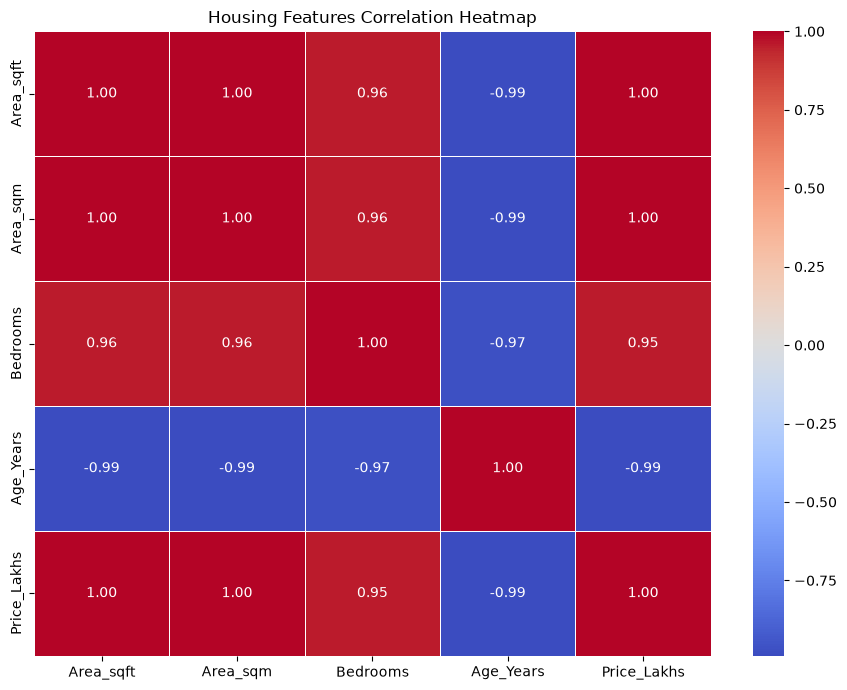


Highly Correlated Feature Pairs:
('Area_sqft', 'Area_sqm', np.float64(1.0))
('Area_sqft', 'Bedrooms', np.float64(0.9578414886923188))
('Area_sqft', 'Age_Years', np.float64(-0.9907497859269361))
('Area_sqft', 'Price_Lakhs', np.float64(0.9991841879459334))
('Area_sqm', 'Bedrooms', np.float64(0.9578414886923187))
('Area_sqm', 'Age_Years', np.float64(-0.9907497859269361))
('Area_sqm', 'Price_Lakhs', np.float64(0.9991841879459334))
('Bedrooms', 'Age_Years', np.float64(-0.9697877906464878))
('Bedrooms', 'Price_Lakhs', np.float64(0.9548193675254313))
('Age_Years', 'Price_Lakhs', np.float64(-0.9863148688777585))


In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create DataFrame
df = pd.DataFrame({
    "Area_sqft": [800, 1000, 1200, 1400, 1600, 1800, 2000, 2200],
    "Area_sqm": [74.32, 92.90, 111.48, 130.06, 148.64, 167.22, 185.80, 204.38],
    "Bedrooms": [1, 2, 2, 3, 3, 3, 4, 4],
    "Age_Years": [25, 20, 18, 15, 12, 10, 8, 6],
    "Price_Lakhs": [25, 32, 38, 45, 52, 60, 68, 75]
})

# Calculate correlation matrix
corr = df.corr()

print("Correlation Matrix:")
print(corr.round(4))

# Plot heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Housing Features Correlation Heatmap")
plt.tight_layout()
plt.show()

# Identify unique feature pairs
threshold = 0.90

pairs = []

columns = corr.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):

        value = corr.iloc[i, j]

        if abs(value) > threshold:
            pairs.append(
                (columns[i], columns[j], value)
            )

print("\nHighly Correlated Feature Pairs:")

for pair in pairs:
    print(pair)


(b) Create two feature sets and compare their relationships.


Feature Set 1:
           Area_sqft  Area_sqm  Bedrooms  Age_Years
Area_sqft      1.000     1.000     0.958     -0.991
Area_sqm       1.000     1.000     0.958     -0.991
Bedrooms       0.958     0.958     1.000     -0.970
Age_Years     -0.991    -0.991    -0.970      1.000

Feature Set 2:
           Area_sqft  Bedrooms  Age_Years
Area_sqft      1.000     0.958     -0.991
Bedrooms       0.958     1.000     -0.970
Age_Years     -0.991    -0.970      1.000


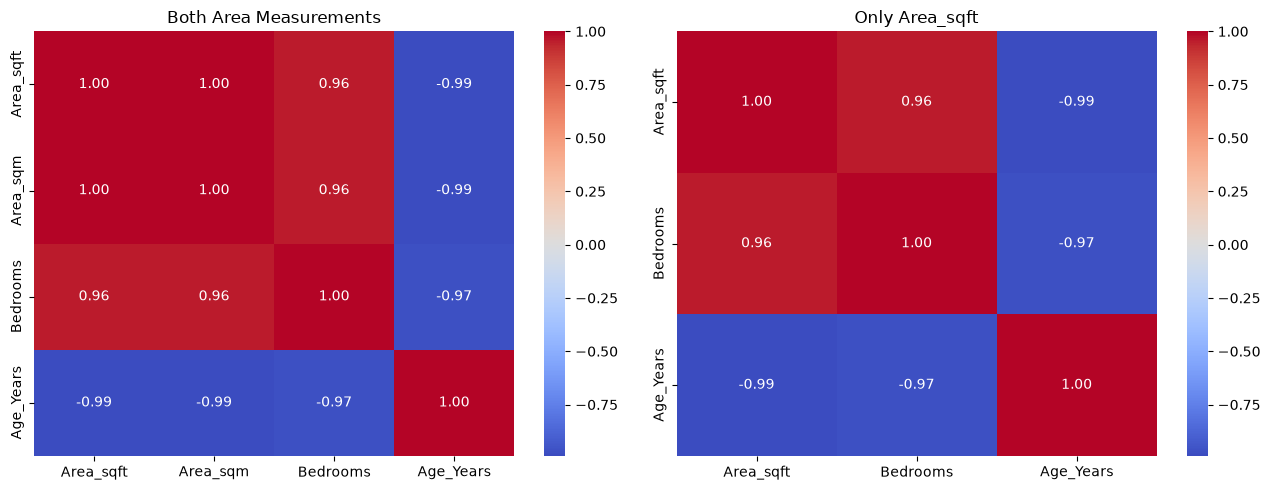

In [4]:

# Feature Set 1: Both area measurements
features_1 = df[
    ['Area_sqft', 'Area_sqm', 'Bedrooms', 'Age_Years']
]

# Feature Set 2: Only Area_sqft
features_2 = df[
    ['Area_sqft', 'Bedrooms', 'Age_Years']
]

# Calculate correlations
corr_1 = features_1.corr()
corr_2 = features_2.corr()

print("Feature Set 1:")
print(corr_1.round(3))

print("\nFeature Set 2:")
print(corr_2.round(3))

# Plot both heatmaps
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)

sns.heatmap(
    corr_1,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Both Area Measurements")

plt.subplot(1, 2, 2)

sns.heatmap(
    corr_2,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Only Area_sqft")

plt.tight_layout()
plt.show()


Q3. Customer Spending Analysis Using the Tips Dataset

Correlation Matrix:
            total_bill     tip    size
total_bill      1.0000  0.6757  0.5983
tip             0.6757  1.0000  0.4893
size            0.5983  0.4893  1.0000


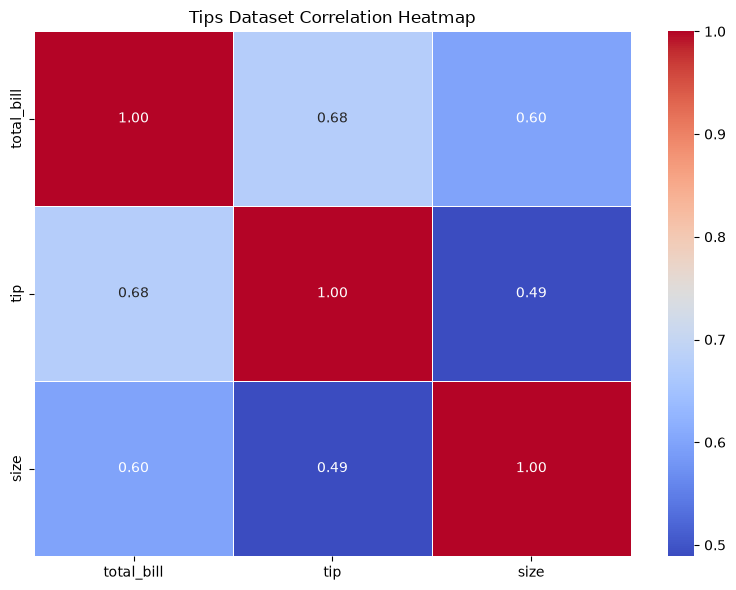


Strongest Relationship:
('total_bill', 'tip')
Correlation: 0.6757341092113648


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Tips dataset
df = sns.load_dataset('tips')

# Select required columns
data = df[['total_bill', 'tip', 'size']]

# Calculate correlation matrix
corr = data.corr()

print("Correlation Matrix:")
print(corr.round(4))

# Create annotated heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Tips Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()

# Identify strongest relationship
pairs = corr.abs().copy()

# Remove diagonal
for i in range(len(pairs)):
    pairs.iloc[i, i] = 0

strongest = pairs.stack().idxmax()

print("\nStrongest Relationship:")
print(strongest)

print("Correlation:",
      corr.loc[strongest[0], strongest[1]])


(b) Create tip_percentage and recalculate the correlation matrix.

Dataset with Tip Percentage:
   total_bill   tip  size  tip_percentage
0       16.99  1.01     2        5.944673
1       10.34  1.66     3       16.054159
2       21.01  3.50     3       16.658734
3       23.68  3.31     2       13.978041
4       24.59  3.61     4       14.680765

Updated Correlation Matrix:
                total_bill     tip    size  tip_percentage
total_bill          1.0000  0.6757  0.5983         -0.3386
tip                 0.6757  1.0000  0.4893          0.3424
size                0.5983  0.4893  1.0000         -0.1429
tip_percentage     -0.3386  0.3424 -0.1429          1.0000


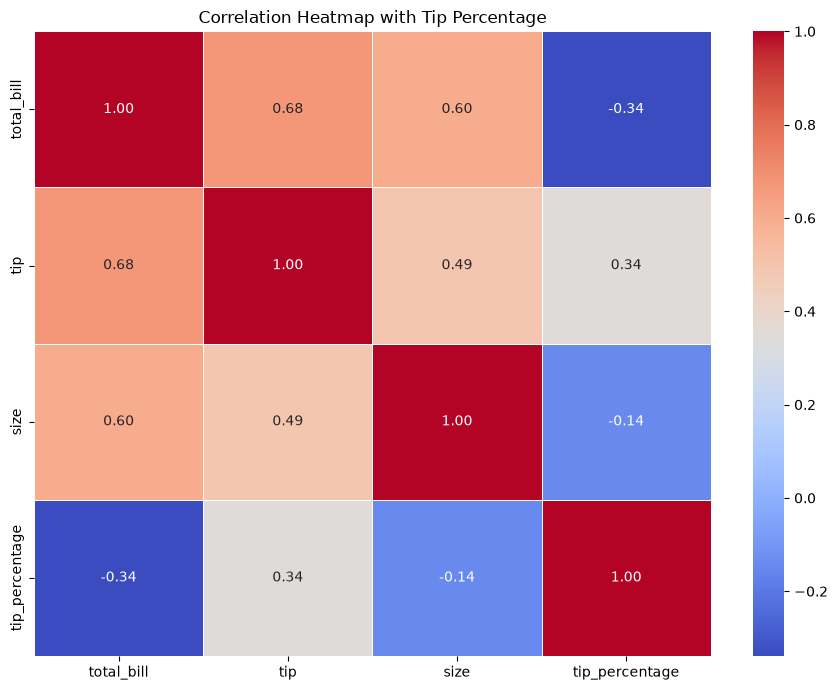

In [6]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset
df = sns.load_dataset('tips')

# Create new column
df['tip_percentage'] = (
    df['tip'] / df['total_bill']
) * 100

print("Dataset with Tip Percentage:")
print(df[['total_bill', 'tip', 'size',
          'tip_percentage']].head())

# Select required columns
data = df[
    ['total_bill', 'tip', 'size', 'tip_percentage']
]

# Recalculate correlation
corr = data.corr()

print("\nUpdated Correlation Matrix:")
print(corr.round(4))

# Create heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap with Tip Percentage")
plt.tight_layout()
plt.show()


Q4. Investigating the Effect of an Outlier

Original Correlation Matrix:
             Advertising   Sales
Advertising       1.0000  0.9999
Sales             0.9999  1.0000


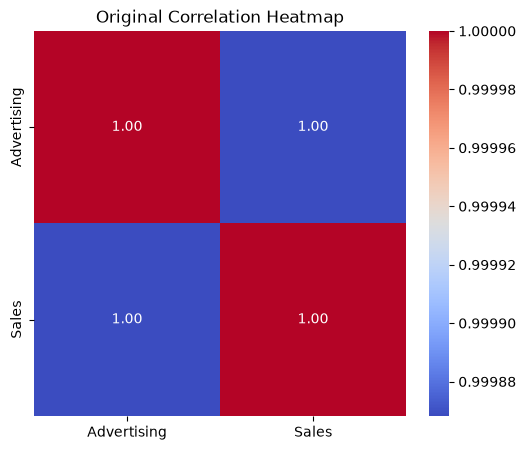


Updated Correlation Matrix:
             Advertising   Sales
Advertising       1.0000  0.0647
Sales             0.0647  1.0000


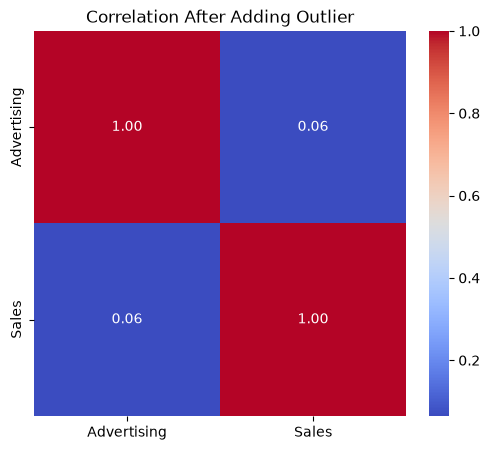


Original Correlation: 0.9998682276680951
Updated Correlation: 0.06468331541572898
Change in Correlation: -0.9351849122523661


In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Original dataset
df = pd.DataFrame({
    "Advertising": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55],
    "Sales": [20, 28, 35, 42, 50, 58, 65, 72, 80, 88]
})

# Original correlation
corr_before = df.corr()

print("Original Correlation Matrix:")
print(corr_before.round(4))

# Original heatmap
plt.figure(figsize=(6, 5))

sns.heatmap(
    corr_before,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Original Correlation Heatmap")
plt.show()


# Add unusual observation
new_data = pd.DataFrame({
    "Advertising": [100],
    "Sales": [10]
})

df_new = pd.concat(
    [df, new_data],
    ignore_index=True
)

# Updated correlation
corr_after = df_new.corr()

print("\nUpdated Correlation Matrix:")
print(corr_after.round(4))

# Updated heatmap
plt.figure(figsize=(6, 5))

sns.heatmap(
    corr_after,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation After Adding Outlier")
plt.show()


# Compare correlation
before = corr_before.loc['Advertising', 'Sales']
after = corr_after.loc['Advertising', 'Sales']

print("\nOriginal Correlation:", before)
print("Updated Correlation:", after)

print("Change in Correlation:", after - before)


(b) Write Python code to flag potential outliers and compare correlations.

In [8]:

# Function to identify outliers using IQR
def detect_outliers(data):

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) |
        (data > upper_bound)
    ]

    return Q1, Q3, IQR, lower_bound, upper_bound, outliers


# Check Advertising
result_adv = detect_outliers(df_new['Advertising'])

print("Advertising Outlier Analysis:")
print("Q1:", result_adv[0])
print("Q3:", result_adv[1])
print("IQR:", result_adv[2])
print("Lower Bound:", result_adv[3])
print("Upper Bound:", result_adv[4])
print("Outliers:", result_adv[5].tolist())


# Check Sales
result_sales = detect_outliers(df_new['Sales'])

print("\nSales Outlier Analysis:")
print("Q1:", result_sales[0])
print("Q3:", result_sales[1])
print("IQR:", result_sales[2])
print("Lower Bound:", result_sales[3])
print("Upper Bound:", result_sales[4])
print("Outliers:", result_sales[5].tolist())


# Compare correlation before and after
print("\nCorrelation Comparison:")

print("Before:", df.corr().loc['Advertising', 'Sales'])

print("After:", df_new.corr().loc['Advertising', 'Sales'])


Advertising Outlier Analysis:
Q1: 22.5
Q3: 47.5
IQR: 25.0
Lower Bound: -15.0
Upper Bound: 85.0
Outliers: [100]

Sales Outlier Analysis:
Q1: 31.5
Q3: 68.5
IQR: 37.0
Lower Bound: -24.0
Upper Bound: 124.0
Outliers: []

Correlation Comparison:
Before: 0.9998682276680951
After: 0.06468331541572898
